# Fitting a spectrum with the R–CPE circuit

This notebook fits a measured spectrum with `EISData.fit`, the iterative fast
branch building (IFBB) routine: it starts from the peaks of $-\mathrm{Im}(Z)$ and
grows R–CPE branches up to `rc_groups`, with `n_restarts` random restarts per solve.
The result is a `FitResults` object holding the fitted `CircuitParameters`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from blowing_bubbles.classes import CircuitParameters, EISData

## Synthesize a noisy measurement

In [2]:
np.random.seed(42)

# Ground-truth R-CPE ladder: [Rs L (R_i C_i)_3]
true_params = CircuitParameters(
    resistance_source=10.0,
    inductance=1e-7,
    inductance_exponent=0.95,
    resistances=np.array([50.0, 20.0, 5.0]),
    capacitances=np.array([1e-4, 1e-3, 1e-2]),
    exponents=np.array([0.98, 0.95, 0.90]),
)

freqs = np.logspace(-2, 5, 100)
z_true = true_params.get_impedance(freqs)
noise = 0.1

data = pd.DataFrame(
    {
        "Freq (Hz)": freqs,
        "Zreal (Ohm)": z_true.real + np.random.normal(0, noise, freqs.size),
        "Zimag (Ohm)": z_true.imag + np.random.normal(0, noise, freqs.size),
    }
)
data.head()

,Freq (Hz),Zreal (Ohm),Zimag (Ohm)
0,0.010000,85.043517,-0.207331
1,0.011768,84.978994,-0.118759
2,0.013849,85.056389,-0.123674
3,0.016298,85.142516,-0.184444
4,0.019179,84.965146,-0.137615


In [3]:
eis = EISData(data)

## Run the fit

`fit()` returns a `FitResults` (a `scipy.optimize.OptimizeResult` subclass) with the
optimized parameters in `result.parameters`, the complex `residuals`, and the
`cost`. Use `seed=` for reproducible restarts.

In [4]:
result = eis.fit(n_restarts=50, rc_groups=3, seed=42)
print(
    "success:",
    result.success,
    "| cost:",
    f"{result.cost:.4e}",
    "| branches:",
    result.n_groups,
)
print(result.parameters)

success: True | cost: 3.0683e-03 | branches: 3
  Resistance Source:        7.5328e-11
  Inductance:               5.8507e-05
  Inductance Exponent:      7.0000e-01
  Resistances:            [9.9926e+00 4.6891e+01 2.8136e+01]
  Capacitances:           [3.9776e-07 1.0006e-04 9.0360e-04]
  Exponents:              [7.3322e-01 9.8834e-01 9.0068e-01]
  Taus:                   [3.9747e-06 4.6918e-03 2.5423e-02]



## Inspect the result

`parameter_uncertainties()` returns the standard errors of the local linearization
at the solution, keyed like `CircuitParameters.as_dict()`. With measurement noise,
individual branches can trade off against `R_s` while the overall curve is still
captured well, so compare `result.cost` and the residuals rather than expecting
exact recovery of every parameter.

In [5]:
print("Fitted vs. true branch resistances:")
print("fitted:", np.round(result.parameters.resistances, 3))
print("true:  ", np.sort(true_params.resistances))
print("\nStandard errors:")
print(result.parameter_uncertainties())

Fitted vs. true branch resistances:
fitted: [ 9.993 46.891 28.136]
true:   [ 5. 20. 50.]

Standard errors:
{'resistance_source': 2918.62950533868, 'inductance': 0.008910462992162131, 'inductance_exponent': 1.3645496688656642, 'resistances': array([2918.58838733,    3.81002966,    3.85461303]), 'capacitances': array([1.49923573e-04, 1.88339804e-06, 1.61267025e-04]), 'exponents': array([4.94797496, 0.00845346, 0.01888284])}


## Nyquist overlay: measurement vs. fit

`plot_nyquist()` draws the data; `CircuitParameters.plot_full_fit()` overlays the
total model curve (dashed) and the individual branch arcs.

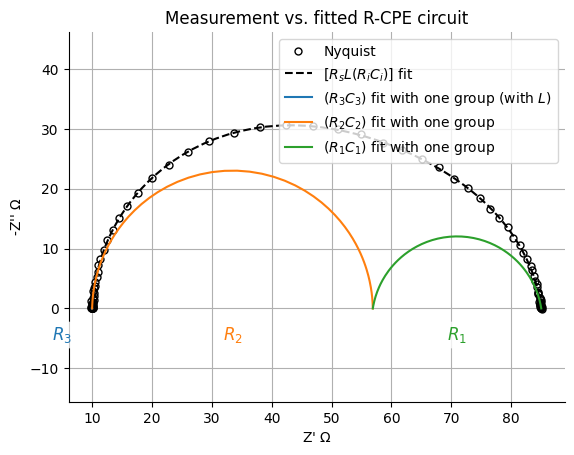

In [6]:
freqs_plot = np.logspace(-2, 5, 200)

fig, ax = plt.subplots()
eis.plot_nyquist(axes=ax)
result.parameters.plot_full_fit(freqs_plot, ax, unit=r"$\Omega$")
ax.legend()
ax.set_title("Measurement vs. fitted R-CPE circuit")
plt.show()

## Save and load fitted parameters

`CircuitParameters.save` / `CircuitParameters.load` round-trip the parameters as JSON.

In [7]:
import os
import tempfile

path = os.path.join(tempfile.mkdtemp(), "fit_params.json")
result.parameters.save(path)
loaded = CircuitParameters.load(path)
print(loaded)

  Resistance Source:        7.5328e-11
  Inductance:               5.8507e-05
  Inductance Exponent:      7.0000e-01
  Resistances:            [9.9926e+00 4.6891e+01 2.8136e+01]
  Capacitances:           [3.9776e-07 1.0006e-04 9.0360e-04]
  Exponents:              [7.3322e-01 9.8834e-01 9.0068e-01]
  Taus:                   [3.9747e-06 4.6918e-03 2.5423e-02]

